# The baseline of the pulses and the Am-241 lines (-82 V, DCRC1pB trigger)

*Draft prepared with Claude Code for A. Villano, 2026-11-03.*

The summed window integral of the events that lie in the patch (the place on the face where the lines of the Am-241 source are, about (10.4, 4.1) us in the re-centred delay plane, 4.5 us radius) falls as the **baseline** of the traces rises (`baseline_mean`, the mean of samples 10 to 450 of the raw trace, ADC counts; from `r76-82v-dcrc1pb.dataset.toml`). At any given baseline the lines are sharp; they slope down together as the baseline goes up. This notebook measures that dependence from the 59.5 keV line and divides it out, for

* **A + B**, the two outer channels;
* **C + D + E + F**, the inner channels;
* **A to F**, all six.

The events and the integrals are those of `window-integral-tail-82v.ipynb` (`r76-82V-window-integral-tail.dataset.toml`: the line fitted to the tail, window samples 400 to 1500). The cuts are the same (real triggers, series `07221113_1159` left out, `bstd` below the cut in all six channels, six valid times within 60 us, no cut on the size). Nothing is calibrated: the energy scale is set by calling the 59.5 keV line of Am-241 the reference position, and the other lines are named from their ratio to it (26.3 keV at 0.44 of it for A + B). Run with the `darkmatter_cli_env` kernel.

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pyarrow.compute as pc
import pyarrow.parquet as pq
from matplotlib import colors

from goldpan.dataset import Dataset

LETTERS = "ABCDEF"
_here = Path.cwd().resolve()
PROCESSING = next(p / "data_analysis" / "R76" / "processing" for p in [_here, *_here.parents] if (p / "data_analysis" / "R76" / "processing").is_dir())
OUT_CUTS = Path(Dataset.open(PROCESSING / "r76-82v-dcrc1pb.dataset.toml").spec.output)          # the cuts, as in positions-small-quiet-82v
OUT_WIN = Path(Dataset.open(PROCESSING / "r76-82V-window-integral-tail.dataset.toml").spec.output)   # the window integral and the heights
PRE = json.loads((OUT_CUTS / "_goldpan.json").read_text(encoding="utf-8"))["streams"]["NAI-S2"]["detector"]["segments"][0]["pretrigger_samples"]
CACHE = Path.home() / "goldsluice-output" / f"relcal-positions-small-82v-p{PRE}.npz"             # the cache of positions-small-quiet-82v
WCACHE = Path.home() / "goldsluice-output" / "relcal-window-integral-tail-82v.npz"               # this notebook's: the window integral and the row check
WCACHE_OLD = Path.home() / "goldsluice-output" / "relcal-window-integral-82v.npz"               # that of window-integral-small-quiet-82v (r76-82V-window-integral)

def field(tab, k, name):
    # one quantity of one channel: the channel is a struct column of the Parquet file
    return pc.struct_field(tab[f"Side2p{k}"].combine_chunks(), name).to_numpy(zero_copy_only=False)

def files(out):
    return sorted((out / "NAI-S2").glob("*_F[0-9][0-9][0-9][0-9].parquet"))

if CACHE.exists():
    z = np.load(CACHE)
    series, trigger, bstd, height, t = z["series"], z["trigger"], z["bstd"], z["height"], z["t"]
else:
    S_, T_, B_, H_, X_ = [], [], [], [], []
    for f in files(OUT_CUTS):
        tab = pq.read_table(f, columns=["series", "trigger_type"] + [f"Side2p{k}" for k in LETTERS])
        S_.append(np.asarray(tab["series"].to_pylist())); T_.append(np.asarray(tab["trigger_type"].to_pylist()))
        B_.append(np.column_stack([field(tab, k, "baseline_std") for k in LETTERS]))
        H_.append(np.column_stack([field(tab, k, "current_max") for k in LETTERS]))
        X_.append(np.column_stack([field(tab, k, "crossing_time_s") for k in LETTERS]) * 1e6)       # microseconds
    series, trigger, bstd, height, t = np.concatenate(S_), np.concatenate(T_), np.vstack(B_), np.vstack(H_), np.vstack(X_)
    np.savez(CACHE, series=series, trigger=trigger, bstd=bstd, height=height, t=t)

def keys(out, window=False):
    # series/dump/event of every row, and (window=True) the window integral of the six channels
    K, X = [], []
    for f in files(out):
        tab = pq.read_table(f, columns=["series", "dump", "event"] + ([f"Side2p{k}" for k in LETTERS] if window else []))
        K.append(np.array([f"{s}/{d}/{e}" for s, d, e in zip(tab["series"].to_pylist(), tab["dump"].to_pylist(), tab["event"].to_pylist())]))
        if window:
            X.append(np.column_stack([field(tab, k, "window_integral") for k in LETTERS]))
    return np.concatenate(K), (np.vstack(X) if window else None)

if WCACHE.exists():
    z = np.load(WCACHE)
    wint, same_rows = z["wint"], bool(z["same_rows"])
else:
    k_cuts, _ = keys(OUT_CUTS)
    k_win, wint = keys(OUT_WIN, window=True)
    same_rows = len(k_cuts) == len(k_win) and bool((k_cuts == k_win).all())
    np.savez(WCACHE, wint=wint, same_rows=same_rows)
assert same_rows and len(wint) == len(series), "the two datasets do not hold the same events in the same order"
real, rand = trigger == "Unknown", trigger == "Physics"
print(f"{len(series):,} events in {len(np.unique(series))} series, the same rows in both datasets: {real.sum():,} real triggers")

1,466,349 events in 8 series, the same rows in both datasets: 1,436,655 real triggers


In [2]:
SATH = np.array([1277, 1095, 589, 930, 680, 883.0])         # saturated height of each channel (saturation-over-time.ipynb)
FRAC = 0.05
BSTD_CUT = np.array([2 * np.median(bstd[rand, i]) for i in range(6)])
WINDOW = 60.0                                               # microseconds: the six times of one pulse lie within this of their median
OFFSET_X, OFFSET_Y = 0.5, 12.0                              # the re-centred plane of positions-small-quiet-82v
BLOB_X, BLOB_Y = 22.0, 2.0                                  # us, in that plane: the densest point of the small events
BLOB_R = 4.0        # us: the tight blob. The density of the small events is 53, 48, 46, 43 per us^2 in 1 us rings out to 4 us, and halves by about 7 us
BLOB_R_OUT = 10.0   # us: the old blob circle (the density falls to a quarter); the comparison set is outside it
EXCLUDE = {"07221113_1159"}
SIZE_CUT = False                                            # True: no channel above FRAC of its saturation (positions-small-quiet-82v)

keep = ~np.isin(series, list(EXCLUDE))
bstd_ok = (bstd < BSTD_CUT).all(axis=1)
small = (height < FRAC * SATH).all(axis=1)
size_ok = small if SIZE_CUT else np.ones(len(series), bool)
finite = np.isfinite(t).all(axis=1)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    one_pulse = (np.abs(t - np.nanmedian(t, axis=1, keepdims=True)) < WINDOW).all(axis=1)
xdel = t[:, 4] - 0.5 * (t[:, 2] + t[:, 3]) + OFFSET_X
ydel = 0.866 * (t[:, 3] - t[:, 2]) + OFFSET_Y
steps = [("real triggers", real & keep), ("+ bstd below the cut in all six channels", real & keep & bstd_ok),
         ("+ no channel above 5 % of its saturation" if SIZE_CUT else "  (no cut on the size)", real & keep & bstd_ok & size_ok),
         ("+ six 20 % times", real & keep & bstd_ok & size_ok & finite),
         ("+ one pulse (times within 60 us)", real & keep & bstd_ok & size_ok & finite & one_pulse)]
for name, m in steps:
    print(f"{name:<46}{m.sum():>11,}")
use = steps[-1][1]
r_blob = np.hypot(xdel - BLOB_X, ydel - BLOB_Y)
blob, rest = use & (r_blob < BLOB_R), use & (r_blob >= BLOB_R_OUT)
randoms = rand & keep
print(f"{'   in the blob':<46}{blob.sum():>11,}")
print(f"{'   between 4 and 10 us (in neither set)':<46}{(use & (r_blob >= BLOB_R) & (r_blob < BLOB_R_OUT)).sum():>11,}")
print(f"{'   outside the blob (beyond 10 us)':<46}{rest.sum():>11,}")
print(f"{'random triggers (for the zero)':<46}{randoms.sum():>11,}")

wsum = wint.sum(axis=1)                                     # all six channels, ADC counts x s
for name, m in (("selected", use), ("blob", blob), ("outside the blob", rest), ("random triggers", randoms)):
    p = np.percentile(wsum[m], [10, 50, 90])
    print(f"{name:>18}: summed window integral 10/50/90 %: " + "  ".join(f"{v:8.5f}" for v in p))

real triggers                                   1,292,982
+ bstd below the cut in all six channels        1,088,121
  (no cut on the size)                          1,088,121
+ six 20 % times                                1,053,964
+ one pulse (times within 60 us)                1,031,670
   in the blob                                      8,861
   between 4 and 10 us (in neither set)            95,769
   outside the blob (beyond 10 us)                927,040
random triggers (for the zero)                     25,511


          selected: summed window integral 10/50/90 %:  0.40083   2.42478   3.92647
              blob: summed window integral 10/50/90 %:  0.01787   0.04465   0.42861
  outside the blob: summed window integral 10/50/90 %:  0.64987   2.60056   3.96936
   random triggers: summed window integral 10/50/90 %: -0.19189  -0.00250   0.08418


In [3]:
# the patch: the events within PATCH_R of the centre of the excess of the 59.5 keV line (found in 2 us bins of the position plane,
# signal window minus sidebands, on the A + B integral); every series, the same place
PATCH_X, PATCH_Y, PATCH_R = 10.4, 4.1, 4.5
patch = use & (np.hypot(xdel - PATCH_X, ydel - PATCH_Y) < PATCH_R)
P = np.flatnonzero(patch)
print(f"{patch.sum():,} patch events ({patch.sum() / use.sum():.1%} of the selected), by series:")
for s_ in sorted(set(np.unique(series)) - EXCLUDE):
    print(f"  {s_}: {(patch & (series == s_)).sum():,}")

129,539 patch events (12.6% of the selected), by series:


  07221111_2153: 16,468
  07221112_0943: 34,969
  07221112_2249: 24,552
  07221114_2141: 9,638


  07221115_0845: 9,992
  07221115_2109: 17,549
  07221116_1003: 16,371


## The baseline of each channel

`baseline_mean` of every channel for the events of the cuts file, read once and cached next to the other caches.

In [4]:
BCACHE = Path.home() / "goldsluice-output" / "relcal-baseline-mean-82v.npz"
if BCACHE.exists():
    bmean = np.load(BCACHE)["bmean"]
else:
    B_ = []
    for f in files(OUT_CUTS):
        tab = pq.read_table(f, columns=[f"Side2p{k}" for k in LETTERS])
        B_.append(np.column_stack([field(tab, k, "baseline_mean") for k in LETTERS]))
    bmean = np.vstack(B_)
    np.savez(BCACHE, bmean=bmean)
assert len(bmean) == len(series)
print("baseline_mean of the selected events (median, 1 to 99 %):")
for i, k in enumerate(LETTERS):
    print(f"  {k}: {np.median(bmean[use, i]):7.1f}  {np.percentile(bmean[use, i], 1):7.1f} .. {np.percentile(bmean[use, i], 99):7.1f}")

baseline_mean of the selected events (median, 1 to 99 %):
  A:  3176.4   3011.6 ..  3873.2


  B:  3193.1   3013.9 ..  3862.5
  C:  3157.1   2997.9 ..  3513.1


  D:  3183.1   3013.8 ..  3785.5
  E:  3176.7   3009.9 ..  3603.8


  F:  3162.7   2959.0 ..  3745.4


## The summed window integral against the baseline

The patch events: the window integral summed over the six channels against the baseline of each channel. The lines are the sloping bands.

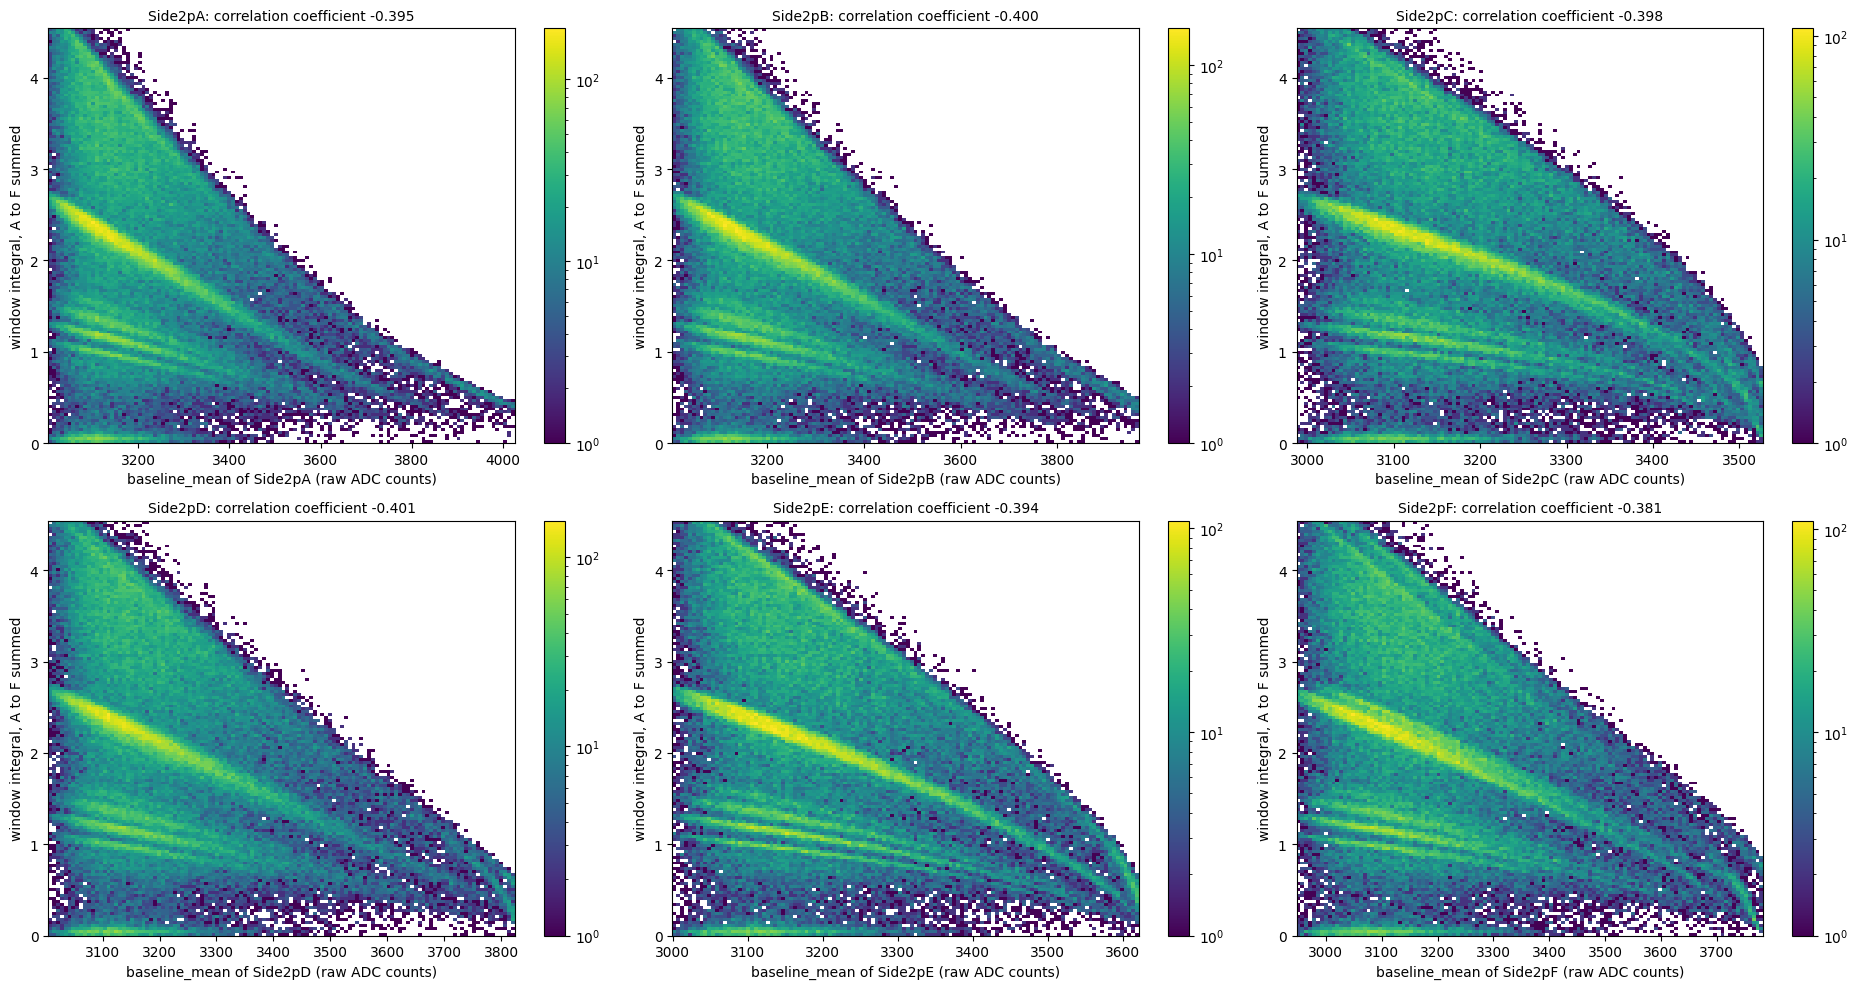

In [5]:
six = wint.sum(axis=1)
fig, axes = plt.subplots(2, 3, figsize=(19, 10))
for i, ax in enumerate(axes.flat):
    x, y = bmean[P, i], six[P]
    h = ax.hist2d(x, y, bins=[120, 140], range=[tuple(np.percentile(x, [0.5, 99.5])), (0, np.percentile(y, 99.5))], cmap="viridis", norm=colors.LogNorm(), cmin=1)
    fig.colorbar(h[3], ax=ax)
    ax.set_xlabel(f"baseline_mean of Side2p{LETTERS[i]} (raw ADC counts)"); ax.set_ylabel("window integral, A to F summed")
    ax.set_title(f"Side2p{LETTERS[i]}: correlation coefficient {np.corrcoef(x, y)[0, 1]:+.3f}", fontsize=10)
fig.tight_layout()
plt.show()

## Measuring the dependence and correcting it

For a quantity `v` (the summed integral) and a baseline `x`: the patch events are sorted by `x` and cut into 24 bins of equal size. In each bin the 59.5 keV peak is found (the highest point of the smoothed spectrum, searched from low to high baseline within -28 % to +4 % of the previous position, then a Gaussian plus a straight line is fitted). A cubic polynomial is fitted to the log of the position against the median baseline of the bins. Every event is then multiplied by `R / f(x)`, where `f` is that curve and `R` its value at the median baseline, so the 59.5 keV line sits at `R` whatever the baseline.

In [6]:
def gfit(v, lo, hi, nb=60):
    # Gaussian plus a straight line in [lo, hi]; returns (the chi2 gained by the Gaussian, its position, its width)
    e = np.linspace(lo, hi, nb + 1); c = 0.5 * (e[1:] + e[:-1]); h, _ = np.histogram(v, bins=e); w = 1 / np.sqrt(np.maximum(h, 1))
    mid = 0.5 * (lo + hi); M0 = np.column_stack([np.ones_like(c), c - mid])
    k0 = np.linalg.lstsq(M0 * w[:, None], h * w, rcond=None)[0]; chi0 = (((M0 @ k0 - h) * w) ** 2).sum()
    best = (1e18, None, None)
    for mu in np.linspace(lo + 0.2 * (hi - lo), hi - 0.2 * (hi - lo), 40):
        for sg in np.linspace(0.01 * (hi - lo), 0.25 * (hi - lo), 14):
            M = np.column_stack([np.exp(-0.5 * ((c - mu) / sg) ** 2), M0])
            k = np.linalg.lstsq(M * w[:, None], h * w, rcond=None)[0]
            if k[0] <= 0:
                continue
            chi = (((M @ k - h) * w) ** 2).sum()
            if chi < best[0]:
                best = (chi, mu, sg)
    return chi0 - best[0], best[1], best[2]

def track(x, v, init, nbins=24):
    # the position of the 59.5 keV peak of v in bins of the baseline x
    order = np.argsort(x); cut = np.linspace(0, len(x), nbins + 1).astype(int)
    xs, ps, prev = [], [], None
    for k in range(nbins):
        sel = order[cut[k]:cut[k + 1]]; vv = v[sel]
        hb = np.linspace(0.05, 3.5, 346); hs = np.convolve(np.histogram(vv, bins=hb)[0], np.ones(5) / 5, "same"); cb = hb[:-1] + 0.005
        lo, hi = init if prev is None else (prev * 0.72, prev * 1.04)
        pos = cb[np.argmax(np.where((cb > lo) & (cb < hi), hs, -1))]
        prev = gfit(vv, pos * 0.8, pos * 1.25)[1]
        xs.append(np.median(x[sel])); ps.append(prev)
    return np.array(xs), np.array(ps)

def correct(v, x, init):
    xs, ps = track(x, v, init)
    co = np.polyfit(xs, np.log(ps), 3)
    f = lambda xx: np.exp(np.polyval(co, xx))
    R = float(f(np.median(x)))
    return v * R / f(x), R, xs, ps, co

QUANT = {  # name: (the integral, the baseline, the search window of the 59.5 keV peak at the lowest baseline, the window of the 26.3 keV peak relative to R)
    "A + B": (wint[P, 0] + wint[P, 1], bmean[P].mean(axis=1), (0.8, 1.5), (0.37, 0.53)),
    "C + D + E + F": (wint[P, 2:].sum(axis=1), bmean[P, 2:].mean(axis=1), (1.4, 2.0), (0.45, 0.65)),
    "A to F": (wint[P].sum(axis=1), bmean[P].mean(axis=1), (2.2, 3.2), (0.38, 0.56)),
}
OUT = {}
print(f"{'':<16}{'59.5 keV: dchi2   sigma/mu':>30}{'26.3 keV (approx.): dchi2   sigma/mu':>46}")
for nm, (v, x, init, lowrel) in QUANT.items():
    S, R, xs, ps, co = correct(v, x, init)
    up, lo_ = gfit(S, 0.83 * R, 1.19 * R, 80), gfit(S, lowrel[0] * R, lowrel[1] * R, 70)
    OUT[nm] = (S, R, xs, ps, co, v, x)
    # before: the same windows around the peak found without the correction
    hb = np.linspace(0.05, 3.5, 346); hs = np.convolve(np.histogram(v, bins=hb)[0], np.ones(5) / 5, "same")
    p0 = (hb[:-1] + 0.005)[np.argmax(np.where(((hb[:-1] + 0.005) > init[0] * 0.7) & ((hb[:-1] + 0.005) < init[1] * 1.0), hs, -1))]
    up0 = gfit(v, 0.83 * p0, 1.19 * p0, 80)
    print(f"{nm:<16}  before {up0[0]:7.0f}  {up0[2] / up0[1]:.3f}   after {up[0]:7.0f}  {up[2] / up[1]:.3f}"
          f"     after {lo_[0]:6.0f}  {lo_[2] / lo_[1]:.3f}    (59.5 keV line at {R:.3f})")

                    59.5 keV: dchi2   sigma/mu          26.3 keV (approx.): dchi2   sigma/mu


A + B             before    2298  0.077   after   14185  0.030     after   1860  0.024    (59.5 keV line at 0.799)


C + D + E + F     before     409  0.088   after   13644  0.023     after    381  0.024    (59.5 keV line at 1.352)


A to F            before     864  0.088   after   14490  0.030     after   1192  0.023    (59.5 keV line at 2.154)


## The spectra, before and after

For each of the three sums: the integral against the baseline with the fitted curve (white points: the peak position in each bin of the baseline), and the spectrum before and after the correction.

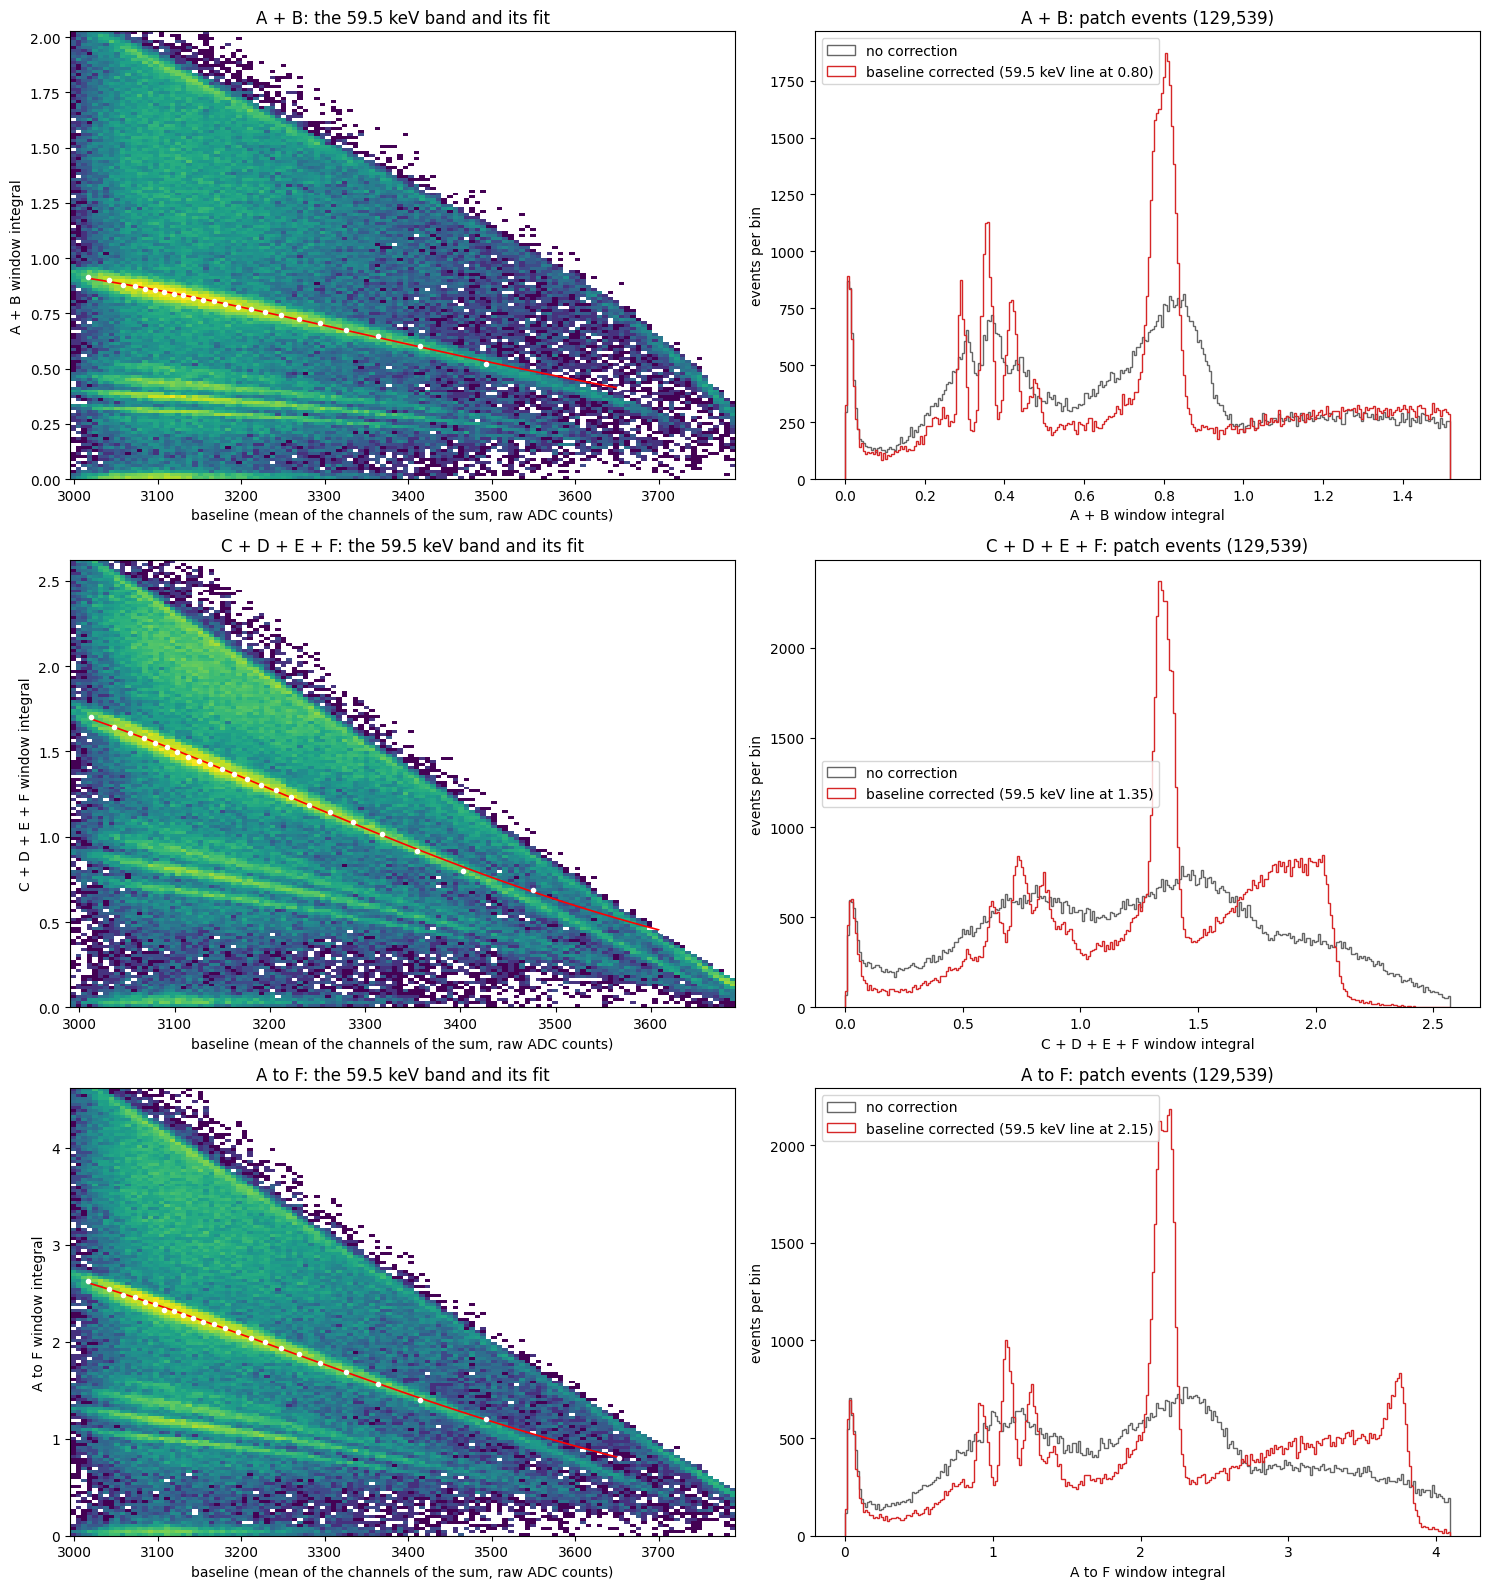

In [7]:
fig, axes = plt.subplots(3, 2, figsize=(15, 16))
for row, (nm, (S, R, xs, ps, co, v, x)) in enumerate(OUT.items()):
    ax = axes[row, 0]
    h = ax.hist2d(x, v, bins=[120, 150], range=[tuple(np.percentile(x, [0.5, 99.5])), (0, np.percentile(v, 99.7))], cmap="viridis", norm=colors.LogNorm(), cmin=1)
    xx = np.linspace(xs.min(), xs.max(), 100)
    ax.plot(xx, np.exp(np.polyval(co, xx)), "r", lw=1.2); ax.plot(xs, ps, "wo", ms=3)
    ax.set_xlabel("baseline (mean of the channels of the sum, raw ADC counts)"); ax.set_ylabel(f"{nm} window integral"); ax.set_title(f"{nm}: the 59.5 keV band and its fit")
    ax = axes[row, 1]
    bb = np.linspace(0, 1.9 * R, 300)
    ax.hist(v, bins=bb, histtype="step", color="0.4", label="no correction"); ax.hist(S, bins=bb, histtype="step", color="C3", label=f"baseline corrected (59.5 keV line at {R:.2f})")
    ax.set_xlabel(f"{nm} window integral"); ax.set_ylabel("events per bin"); ax.legend(); ax.set_title(f"{nm}: patch events ({len(P):,})")
fig.tight_layout()
plt.show()

## The spectrum summed across all channels

A to F, baseline corrected (the mean of the six baselines), on its own and by series.

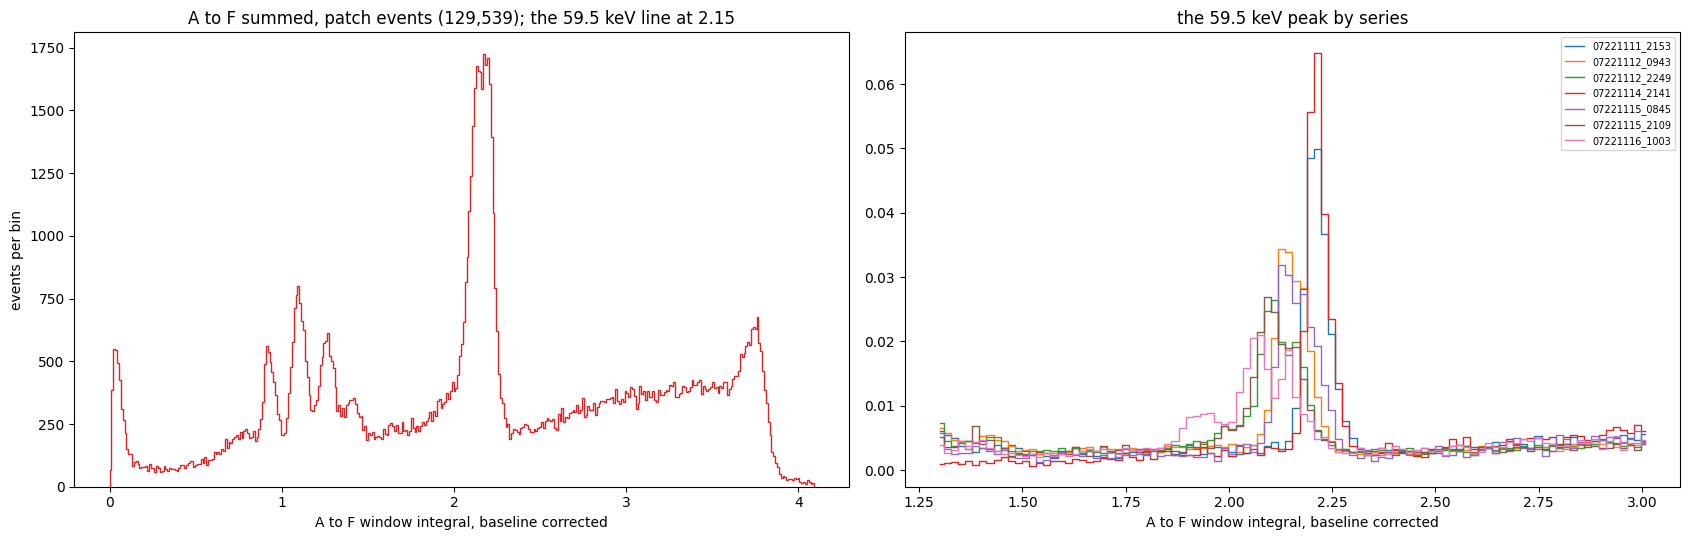

59.5 keV peak position by series (A to F, baseline corrected):


  07221111_2153: 2.224   sigma/mu 0.017
  07221112_0943: 2.144   sigma/mu 0.017
  07221112_2249: 2.124   sigma/mu 0.029
  07221114_2141: 2.224   sigma/mu 0.017


  07221115_0845: 2.164   sigma/mu 0.017
  07221115_2109: 2.104   sigma/mu 0.029
  07221116_1003: 2.064   sigma/mu 0.041


In [8]:
S, R, xs, ps, co, v, x = OUT["A to F"]
ser = series[P]
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
bb = np.linspace(0, 1.9 * R, 380)
axes[0].hist(S, bins=bb, histtype="step", color="C3"); axes[0].set_xlabel("A to F window integral, baseline corrected"); axes[0].set_ylabel("events per bin")
axes[0].set_title(f"A to F summed, patch events ({len(P):,}); the 59.5 keV line at {R:.2f}")
for s_ in sorted(set(np.unique(series)) - EXCLUDE):
    m = ser == s_; bs = np.linspace(0.6 * R, 1.4 * R, 101); h_, _ = np.histogram(S[m], bins=bs)
    axes[1].step(bs[:-1] + 0.004 * R, h_ / m.sum(), where="mid", lw=1, label=s_)
axes[1].set_title("the 59.5 keV peak by series"); axes[1].set_xlabel("A to F window integral, baseline corrected"); axes[1].legend(fontsize=7)
fig.tight_layout()
plt.show()
print("59.5 keV peak position by series (A to F, baseline corrected):")
for s_ in sorted(set(np.unique(series)) - EXCLUDE):
    m = ser == s_; a = gfit(S[m], 0.7 * R, 1.3 * R, 80)
    print(f"  {s_}: {a[1]:.3f}   sigma/mu {a[2] / a[1]:.3f}")

## The lines and the energy calibration (A + B)

Peaks of the baseline-corrected A + B spectrum: local maxima of the smoothed histogram that stand 4 sigma above a running-median background, each fitted with a Gaussian plus a line. Three of them are named with confidence and make the calibration: Ag K-alpha (22.16 keV, possibly blended with Np L-gamma at 20.8 keV), and the two Am-241 gamma lines at 26.34 and 59.54 keV. The other peaks are placed on the scale they give.

In [9]:
from numpy.lib.stride_tricks import sliding_window_view as swv
S, R = OUT["A + B"][0], OUT["A + B"][1]
bw = 0.004 * R / 0.8
e = np.arange(0.05 * R, 1.45 * R, bw); c = 0.5 * (e[1:] + e[:-1]); h, _ = np.histogram(S, bins=e)
hs = np.convolve(h, np.array([1, 2, 3, 2, 1]) / 9, "same")
bgd = np.median(swv(np.pad(hs, 30, mode="edge"), 61), axis=1)
pk = [i for i in range(3, len(h) - 3) if hs[i] == hs[i - 3:i + 4].max() and hs[i] - bgd[i] > 4 * np.sqrt(max(bgd[i], 1))]
peaks = []
for i in pk:
    d, mu, sg = gfit(S, c[i] - 0.06 * R, c[i] + 0.06 * R, 40)
    peaks.append((mu, sg, d))
    print(f"position {mu:.4f}  sigma {sg:.4f} ({sg / mu:.3f})  chi2 gained {d:6.0f}")
peaks = np.array(peaks)

position 0.2928  sigma 0.0080 (0.027)  chi2 gained   1111
position 0.3542  sigma 0.0098 (0.028)  chi2 gained   2301
position 0.4181  sigma 0.0116 (0.028)  chi2 gained    915


position 0.4794  sigma 0.0098 (0.020)  chi2 gained    121
position 0.8040  sigma 0.0240 (0.030)  chi2 gained   2752


free fit: 0.01363 per keV, offset -0.0071 (-0.52 keV);  through zero: 0.01346 per keV
residuals (keV), free fit:      [-0.15  0.17 -0.02]
residuals (keV), through zero:  [-0.41 -0.04  0.17]


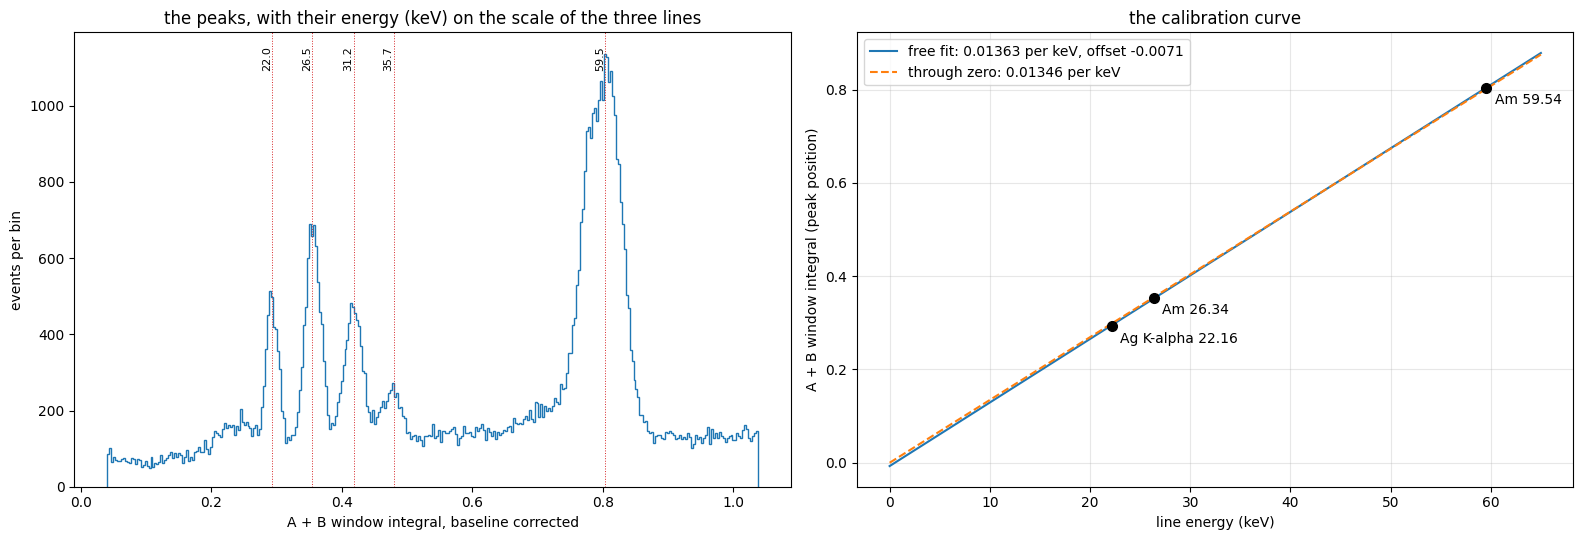

In [10]:
# the three named lines: Ag K-alpha, Am 26.34, Am 59.54 keV
KNOWN = {"Ag K-alpha 22.16": 22.16, "Am 26.34": 26.34, "Am 59.54": 59.54}
Ek = np.array(list(KNOWN.values()))
pos = np.array([peaks[np.argmin(np.abs(peaks[:, 0] - x0)), 0] for x0 in (0.293, 0.354, 0.804)])
m, b = np.polyfit(Ek, pos, 1); m0 = (Ek @ pos) / (Ek @ Ek)
print(f"free fit: {m:.5f} per keV, offset {b:+.4f} ({b / m:+.2f} keV);  through zero: {m0:.5f} per keV")
print("residuals (keV), free fit:     ", np.round((pos - (m * Ek + b)) / m, 2))
print("residuals (keV), through zero: ", np.round((pos - m0 * Ek) / m0, 2))
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
bb = np.linspace(0.05 * R, 1.3 * R, 330)
axes[0].hist(S, bins=bb, histtype="step", color="C0")
for mu, sg, d in peaks:
    axes[0].axvline(mu, color="C3", lw=0.7, ls=":"); axes[0].text(mu, axes[0].get_ylim()[1] * 0.97, f"{(mu - b) / m:.1f}", rotation=90, ha="right", va="top", fontsize=8)
axes[0].set_xlabel("A + B window integral, baseline corrected"); axes[0].set_ylabel("events per bin"); axes[0].set_title("the peaks, with their energy (keV) on the scale of the three lines")
g_ = np.linspace(0, 65, 50)
axes[1].plot(g_, m * g_ + b, "C0-", label=f"free fit: {m:.5f} per keV, offset {b:+.4f}")
axes[1].plot(g_, m0 * g_, "C1--", label=f"through zero: {m0:.5f} per keV")
axes[1].plot(Ek, pos, "ko", ms=7, zorder=3)
for (n, E_), x_ in zip(KNOWN.items(), pos): axes[1].annotate(n, (E_, x_), textcoords="offset points", xytext=(6, -12))
axes[1].set_xlabel("line energy (keV)"); axes[1].set_ylabel("A + B window integral (peak position)"); axes[1].legend(); axes[1].grid(alpha=.3)
axes[1].set_title("the calibration curve")
fig.tight_layout()
plt.show()